# Media Sentiment & Narrative Divergence

## Project Overview

This project examines how Ghanaian and international media sources reported on Operation Blackout / Operation Cyber Hunt.

The analysis focuses on:
- Media sentiment
- Narrative framing
- Recurring keywords
- Differences in how sources presented the operation

## Research Objective

To explore how different media sources framed the operation, particularly the question of whether it was Ghana-led or part of a wider FBI-led international operation.

## Dataset

The dataset contains five prepared source summaries, including an official statement from Ghana's Cyber Security Authority and reports from Ghanaian news outlets.

## Methodology

The project uses keyword-based sentiment analysis and narrative-framing classification.

**Important limitation:** The results are preliminary. The dataset contains only five prepared summaries, some of which repeat the same official position. The keyword-based method does not represent a full understanding of sentiment or media bias.

## 1. Importing Libraries and Loading the Dataset

We will use Python libraries to load, inspect, and analyze the prepared dataset.

The main library used is pandas.

In [1]:
import pandas as pd

# Load the prepared dataset
df = pd.read_csv("../Data/processed/articles_dataset.csv")

# Display the first five rows
df.head()

,source,source_type,text
0,Cyber Security Authority,Official Statement,"SOURCE: Cyber Security Authority (CSA), Ghana\..."
1,3news_operation_blackout,News Article,Summary: Cyber Security Authority Rejects Port...
2,citi_news_fbi_account_operation_blackout,News Article,# Summary: FBI's Account of Operation Blackout...
3,citi_news_operation_cyber_hunt,News Article,# Summary: CSA Rejects FBI’s Account of Ghana’...
4,myjoyonline_operation_blackout,News Article,"# Summary: Ghana Led Operation Blackout, Not F..."


In [2]:
# Check the dataset size
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5, 3)

Column names:
['source', 'source_type', 'text']

Missing values:
source         0
source_type    0
text           0
dtype: int64


In [3]:
# Count the different types of sources
source_counts = df["source_type"].value_counts()

print(source_counts)

source_type
News Article          4
Official Statement    1
Name: count, dtype: int64


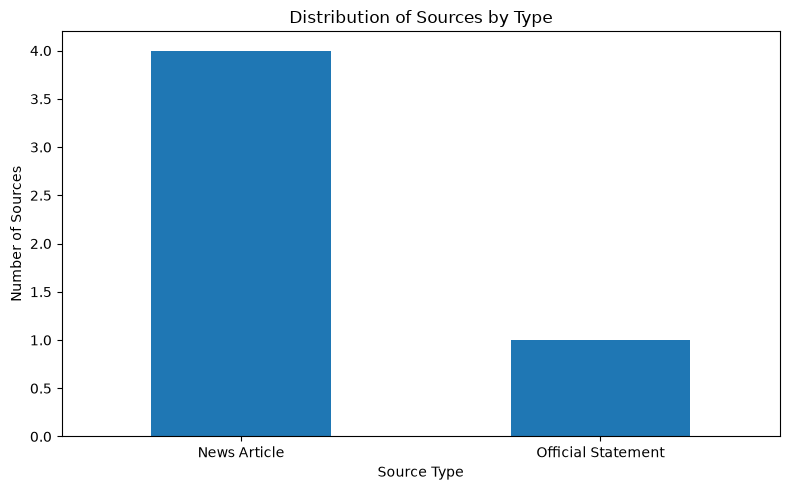

In [4]:
import matplotlib.pyplot as plt

source_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Distribution of Sources by Type")
plt.xlabel("Source Type")
plt.ylabel("Number of Sources")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
# Calculate the number of words in each source
df["word_count"] = df["text"].apply(lambda text: len(text.split()))

# Display source names and word counts
df[["source", "word_count"]]

,source,word_count
0,Cyber Security Authority,156
1,3news_operation_blackout,320
2,citi_news_fbi_account_operation_blackout,260
3,citi_news_operation_cyber_hunt,396
4,myjoyonline_operation_blackout,253


## 2. Initial Dataset Observations

The dataset contains five prepared source summaries: four news articles and one official statement.

The summaries vary in length, ranging from 156 to 396 words. This difference is important because longer texts may contain more keywords and could influence keyword-based sentiment analysis.

The dataset contains no missing values. However, the small sample size and the use of prepared summaries limit how widely the findings can be generalized.

## 3. Sentiment Analysis

This section examines the sentiment labels generated by our keyword-based sentiment analysis script.

The results classify each source as Positive, Negative, or Neutral.

In [6]:
# Load the sentiment analysis results
sentiment_df = pd.read_csv("../Data/processed/sentiment_results.csv")

# Display the results
sentiment_df

,source,source_type,text,positive_keyword_count,negative_keyword_count,sentiment_label,narrative_framing
0,Cyber Security Authority,Official Statement,"SOURCE: Cyber Security Authority (CSA), Ghana\...",1,1,Neutral,Ghana-led framing
1,3news_operation_blackout,News Article,Summary: Cyber Security Authority Rejects Port...,1,2,Negative,Ghana-led framing
2,citi_news_fbi_account_operation_blackout,News Article,# Summary: FBI's Account of Operation Blackout...,1,1,Neutral,FBI/international framing
3,citi_news_operation_cyber_hunt,News Article,# Summary: CSA Rejects FBI’s Account of Ghana’...,1,2,Negative,Ghana-led framing
4,myjoyonline_operation_blackout,News Article,"# Summary: Ghana Led Operation Blackout, Not F...",1,1,Neutral,Ghana-led framing


### 3.1 Sentiment Distribution

The chart below shows how the five prepared source summaries were classified by the keyword-based sentiment analysis.

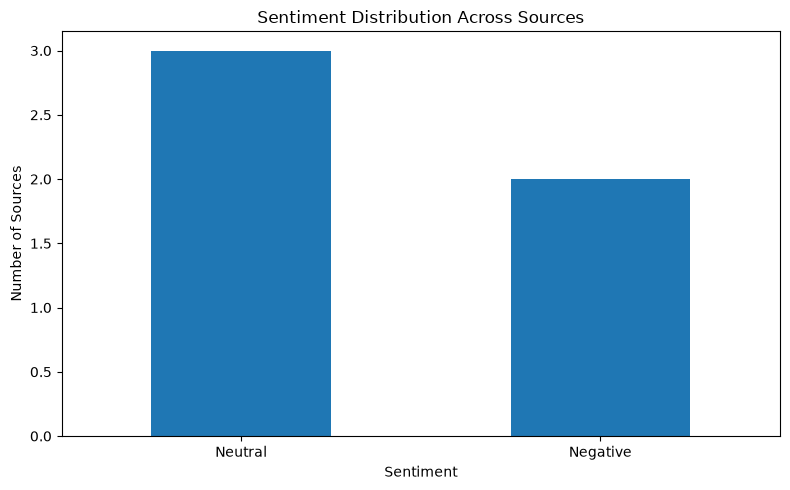

In [7]:
# Count sentiment labels
sentiment_counts = sentiment_df["sentiment_label"].value_counts()

# Plot sentiment distribution
sentiment_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Sentiment Distribution Across Sources")
plt.xlabel("Sentiment")
plt.ylabel("Number of Sources")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.2 Narrative Framing Distribution

This section examines whether each source primarily presented the operation as Ghana-led or as part of an FBI/international effort.

The classification is based on keyword comparisons in the prepared summaries.

narrative_framing
Ghana-led framing            4
FBI/international framing    1
Name: count, dtype: int64


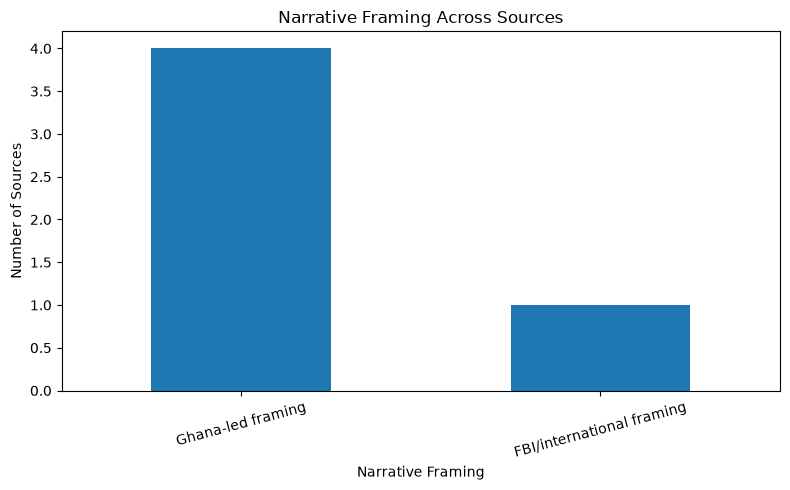

In [8]:
# Count narrative framing categories
framing_counts = sentiment_df["narrative_framing"].value_counts()

# Display counts
print(framing_counts)

# Plot narrative framing
framing_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Narrative Framing Across Sources")
plt.xlabel("Narrative Framing")
plt.ylabel("Number of Sources")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 4. Comparing Sentiment and Narrative Framing

This section compares the sentiment labels with the narrative framing assigned to each source.

In [9]:
# Compare sentiment and narrative framing by source
comparison = sentiment_df[
    ["source", "sentiment_label", "narrative_framing"]
]

comparison

,source,sentiment_label,narrative_framing
0,Cyber Security Authority,Neutral,Ghana-led framing
1,3news_operation_blackout,Negative,Ghana-led framing
2,citi_news_fbi_account_operation_blackout,Neutral,FBI/international framing
3,citi_news_operation_cyber_hunt,Negative,Ghana-led framing
4,myjoyonline_operation_blackout,Neutral,Ghana-led framing


## 5. Key Findings

The preliminary analysis reveals the following:

1. **Sentiment distribution:** Three sources were classified as Neutral, while two were classified as Negative. No source was classified as Positive.

2. **Narrative framing:** Four sources were classified as Ghana-led, while one was classified as FBI/international.

3. **Different dimensions:** Sentiment and narrative framing do not measure the same thing. A source can use Ghana-led framing while receiving a Neutral or Negative sentiment label.

4. **Dataset limitations:** The analysis uses only five prepared summaries. Some sources repeat the Cyber Security Authority's position, meaning they do not represent five fully independent perspectives.

5. **Methodological limitations:** The analysis uses keyword counting, which cannot fully understand context, sarcasm, quotations, or the overall meaning of an article.

## 6. Conclusion

The preliminary findings show that Ghana-led framing appears more frequently than FBI/international framing in the five selected source summaries.

However, the findings should not be generalized to all Ghanaian or international media coverage. A larger dataset containing complete articles and more independent perspectives would be needed for a stronger comparison.

## 7. Sources and References

The analysis is based on five prepared source summaries:

1. Cyber Security Authority (CSA) — Official statement.
2. 3News — Operation Blackout news report.
3. Citi Newsroom — Report on the FBI's account of Operation Blackout.
4. Citi Newsroom — Report on the CSA's response to the FBI's account.
5. MyJoyOnline — Report on Ghana's leadership of Operation Blackout.

The summaries were prepared for this research project. They are not substitutes for the complete original publications.

For verification and further research, the original publication links, authors, and publication dates should be recorded in the project's source log.